In [1]:
import numpy as np
import struct
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
with open('build/mt/boom_m_1.T3/prof.bin', 'rb') as f:
    data = f.read()
threads, = struct.unpack('q', data[:8])
data = np.frombuffer(data[8:], dtype=np.uint64).reshape(threads, -1, 6)
data = data[:, 150000:, :] - data[:, 150000, None, 0, None]
cost = np.diff(data, axis=-1)

ValueError: cannot reshape array of size 72001580 into shape (3,newaxis,6)

In [19]:
data[0].max() - data[0].min()

np.uint64(16107372668)

In [150]:
part1 = cost[:, :10]
part2 = cost[:, 100000:100010]
offseted = part2.reshape(cost.shape[0], -1)

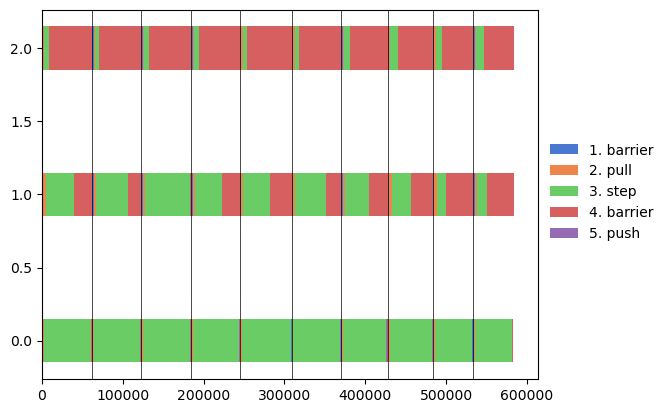

In [151]:
pos = np.arange(offseted.shape[0])
palette = sns.color_palette('muted', 6)
names = [
    '1. barrier',
    '2. pull',
    '3. step',
    '4. barrier',
    '5. push',
]
for p in range(offseted.shape[1]):
    plt.barh(
        pos,
        offseted[:, p],
        left=offseted[:, :p].sum(axis=1),
        color=palette[p % len(names)],
        height=0.3,
        label=names[p] if p < len(names) else None
    )
    if p % len(names) == 0:
        plt.axvline(offseted[:, :p].sum(axis=1).mean(), color='black', lw=0.5)
plt.gcf().legend(loc='center right', bbox_to_anchor=(1.1, 0.5), frameon=False)

In [152]:
names = [
    '1. barrier',
    '2. pull',
    '3. step',
    '4. barrier',
    '5. push',
]

In [153]:
cost = np.diff(data, axis=-1)
avg_cost = cost.mean(axis=1)

([<matplotlib.patches.Wedge at 0x7649621a0690>,
 [Text(1.096813054502168, 0.08367271642312389, '1. barrier'),
  Text(1.0651170089110564, 0.2748194995417259, '2. pull'),
  Text(-0.3714493253107079, 1.0353865938509248, '3. step'),
  Text(0.17380448042075133, -1.0861823063306053, '4. barrier'),
  Text(1.09995127702208, -0.010353172339709952, '5. push')],
 [Text(0.5982616660920915, 0.04563966350352212, '2.4%'),
  Text(0.5809729139514852, 0.14990154520457774, '3.2%'),
  Text(-0.20260872289674975, 0.5647563239186862, '49.7%'),
  Text(0.09480244386586435, -0.5924630761803301, '44.4%'),
  Text(0.5999734238302253, -0.005647184912569064, '0.3%')])

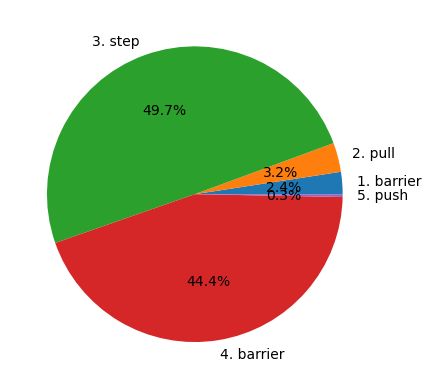

In [154]:
plt.pie(avg_cost.mean(axis=0), labels=names, autopct='%1.1f%%')

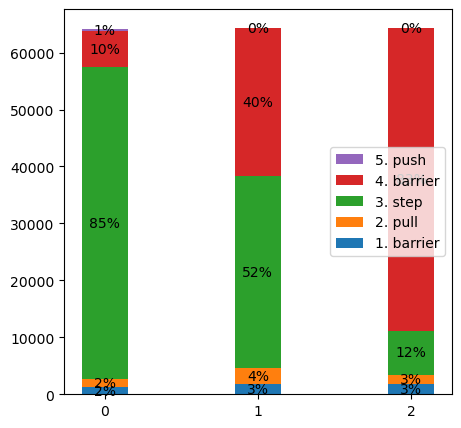

In [155]:
x = np.arange(cost.shape[0])
items = []
plt.figure(figsize=(5,5))
total_cost = np.sum(avg_cost, axis=-1)
for i in range(5):
    bottom = np.sum(avg_cost[:, :i], axis=-1)
    item = plt.bar(x, avg_cost[:, i], bottom=bottom, width=0.3)
    for j in range(cost.shape[0]):
        pct = avg_cost[j, i] / total_cost[j]
        plt.text(x[j], bottom[j] + avg_cost[j, i] / 2, f'{pct:.0%}', ha='center', va='center')
    items.append(item)
plt.legend(items[::-1], names[::-1])
plt.xticks(x, x)
plt.show()

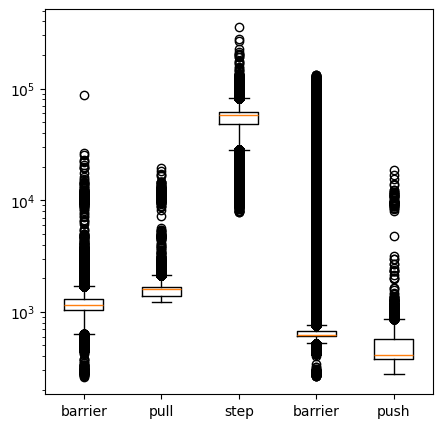

In [156]:
plt.figure(figsize=(5,5))
plt.boxplot(cost[0, :], tick_labels=['barrier', 'pull', 'step', 'barrier', 'push'])
plt.yscale('log')